# 🛣️ RoadScan AI — Label-Free Road Surface Distress Detection for Smart Mobility

**Find and map cracks, potholes, patches and stains on road surfaces with a model trained only on intact road**, then turn it into a road-condition report and check whether it is fast enough to run on a survey vehicle.

| | |
|---|---|
| **Problem** | Road agencies, municipalities and fleet operators need continuous road-condition monitoring (survey vehicles, dashcams, buses as sensors). Pixel-labelling road distress is slow and expensive, and every city, camera and road surface looks different. |
| **Approach** | Learn what *healthy road* looks like and flag anything else. Three label-free detectors are compared: a classical crack-detection pipeline (black-hat morphology + Frangi ridge filter), **PatchCore** (memory-bank anomaly detection, implemented from scratch) and a **U-Net trained on procedurally generated road distress** (random-walk cracks + Perlin potholes/patches/stains). Their calibrated maps are **fused**. A U-Net trained on the *real* crack labels serves as an upper-bound reference. |
| **Mobility angle** | Full-image **road-condition maps** with flagged tiles, crack length (skeletonization) and a severity grade; thresholds set from healthy road only (3σ rule); **ONNX + INT8** for in-vehicle CPUs, with latency translated into **maximum survey speed (km/h)**; a cross-city test (train on one dataset, test on another); and a **Gradio** demo. |
| **Data** | [DeepCrack](https://github.com/yhlleo/DeepCrack) (537 pavement/concrete images with pixel masks) · optional second city: [CrackForest](https://github.com/cuilimeng/CrackForest-dataset) (118 urban-road images, Beijing). Both are for non-commercial research/education. |
| **Cost** | Free Colab **T4 GPU**, ~25–30 min end-to-end. Nothing is stored on your computer. |

```
 road images ──► 128-px tiles ──► crack-free tiles only (training) ──────────────┐
                                                                                 ▼
 ┌──────────────────┐  ┌───────────────────────┐  ┌────────────────────────────────┐
 │ Classical        │  │ PatchCore             │  │ Road-distress synthesizer      │
 │ CLAHE + black-hat│  │ WRN50 patch features  │  │ random-walk cracks + Perlin    │
 │ + Frangi ridges  │  │ + greedy coreset + kNN│  │ potholes/stains ─► U-Net (R18) │
 └────────┬─────────┘  └──────────┬────────────┘  └───────────────┬────────────────┘
          │                       └──────── z-score fusion ────────┘
          ▼                                    ▼
     baseline map        tile maps ─► stitched road map ─► 3σ threshold (healthy road only)
                                       ▼
   crack length · severity · tile metrics · cross-city test · ONNX/INT8 survey speed · Gradio
```

**Before you start:** `Runtime → Change runtime type → T4 GPU`, then `Runtime → Run all`.

## 0 · Setup

In [12]:
!pip -q install gradio onnx onnxscript onnxruntime

In [13]:
import os, gc, glob, json, math, time, copy, random, zipfile, subprocess, warnings
import numpy as np, cv2, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.models as tvm
import torchvision.transforms.functional as TF
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve
from skimage.filters import frangi
from skimage.morphology import skeletonize
warnings.filterwarnings('ignore')

CFG = {
    'dataset': 'deepcrack',      # 'deepcrack' (main) or 'cfd' (CrackForest, urban roads)
    'tile': 128,                 # tile size in original pixels (a road-survey grid cell)
    'img_size': 256,             # tiles are upsampled 2x so thin cracks survive the CNN stride
    'min_crack_px': 30,          # test tile counts as "distressed" above this many crack pixels
    'val_frac': 0.1,             # share of healthy training tiles held out for calibration
    'max_train_tiles': 1500,     # healthy tiles kept for training (RAM budget)
    'bank_tiles': 300,           # healthy tiles in the PatchCore memory bank
    'max_test_images': 100,      # test road images (tiled) used for evaluation
    'coreset_ratio': 0.10,
    'seg_steps': 1500, 'seg_batch': 8, 'seg_lr': 3e-4,
    'p_crack_synth': 0.6,        # share of synthetic distress that is a crack (rest: potholes/patches/stains)
    'smooth_sigma': 2,           # map smoothing; small because cracks are thin
    'run_supervised_ref': True,  # also train on REAL crack labels as an upper-bound reference
    'frame_coverage_m': 3.0,     # metres of road per camera frame, for the survey-speed estimate
    'seed': 42,
    'data_dir': '/kaggle/working/data',
    'out_dir': '/kaggle/working/outputs',
}
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
USE_AMP = DEVICE == 'cuda'
S, T = CFG['img_size'], CFG['tile']
os.makedirs(CFG['out_dir'], exist_ok=True)
FIG = lambda name: os.path.join(CFG['out_dir'], name)

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(CFG['seed'])
print('torch', torch.__version__, '| device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE == 'cuda' else '')
if DEVICE == 'cpu':
    print('⚠️  No GPU found: Runtime → Change runtime type → T4 GPU (free).')

torch 2.11.0+cu130 | device: cuda Tesla T4


## 1 · Data: road images → survey tiles

Road images are cut into **128 × 128 px tiles** (like the grid cells of a pavement survey) and upsampled to 256 px for the networks.

* **Training:** only tiles with **zero** labelled crack pixels from the training images. No distress labels are used.
* **Calibration:** 10% of those healthy tiles are held out to set thresholds.
* **Test:** tiles from unseen test images. A tile is *distressed* if it has ≥ 30 crack pixels and *healthy* if it has none. Borderline tiles with only a few crack pixels are excluded, since their label is ambiguous.

**Manual fallback:** if a `git clone` fails, download the repo as a ZIP from GitHub, upload it, and extract it to `/content/data/<dataset>`.

In [14]:
DATASETS = {'deepcrack': 'https://github.com/yhlleo/DeepCrack.git',
            'cfd': 'https://github.com/cuilimeng/CrackForest-dataset.git'}
IMG_EXTS = ('.png', '.jpg', '.jpeg', '.bmp')

def fetch(name):
    dst = os.path.join(CFG['data_dir'], name)
    if not os.path.isdir(dst):
        print(f'Cloning {name} ...')
        subprocess.run(['git', 'clone', '--depth', '1', DATASETS[name], dst], check=True)
    for z in glob.glob(f'{dst}/**/*.zip', recursive=True):
        out = os.path.splitext(z)[0] + '_unzipped'
        if not os.path.isdir(out):
            try:
                with zipfile.ZipFile(z) as f:
                    f.extractall(out)
            except zipfile.BadZipFile:
                print('⚠️ could not unzip', z, '(see manual fallback above)')
    return dst

def find_dir(root, name):
    c = sorted(d for d in glob.glob(f'{root}/**/{name}', recursive=True) if os.path.isdir(d))
    return c[0] if c else ''

def pair_dir(img_dir, lab_dir):
    if not img_dir or not lab_dir:
        return []
    labs = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(f'{lab_dir}/*')}
    out = []
    for p in sorted(glob.glob(f'{img_dir}/*')):
        s = os.path.splitext(os.path.basename(p))[0]
        if p.lower().endswith(IMG_EXTS) and s in labs:
            out.append((p, labs[s]))
    return out

def read_label(p):
    if p.endswith('.mat'):              # CrackForest: MATLAB struct, Segmentation 1 = road, 2 = crack
        from scipy.io import loadmat
        gt = loadmat(p, squeeze_me=True, struct_as_record=False)['groundTruth']
        if isinstance(gt, np.ndarray) and gt.dtype == object:
            gt = gt.flat[0]
        seg = gt.Segmentation if hasattr(gt, 'Segmentation') else gt
        return np.asarray(seg, dtype=np.float32) > 1
    return cv2.imread(p, cv2.IMREAD_GRAYSCALE) > 127

def read_pair(ip, lp):
    im = cv2.cvtColor(cv2.imread(ip, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    m = read_label(lp)
    if m.shape != im.shape[:2]:
        m = cv2.resize(m.astype(np.uint8), (im.shape[1], im.shape[0]), interpolation=cv2.INTER_NEAREST) > 0
    return im, m

def list_pairs(name):
    root = fetch(name)
    if name == 'deepcrack':
        tr = pair_dir(find_dir(root, 'train_img'), find_dir(root, 'train_lab'))
        te = pair_dir(find_dir(root, 'test_img'), find_dir(root, 'test_lab'))
    else:
        allp = pair_dir(find_dir(root, 'image'), find_dir(root, 'groundTruth'))
        perm = np.random.default_rng(CFG['seed']).permutation(len(allp))
        allp = [allp[i] for i in perm]
        k = int(0.6 * len(allp)); tr, te = allp[:k], allp[k:]
    assert tr and te, f'No image/label pairs found for {name}: check the folder layout or use the manual fallback.'
    return tr, te

def tile_pos(L, t):
    p = list(range(0, L - t + 1, t))
    if p[-1] != L - t:
        p.append(L - t)          # last tile aligned to the border (small overlap)
    return p

def make_tiles(pairs):
    tiles, masks, meta = [], [], []
    for k, (ip, lp) in enumerate(pairs):
        im, m = read_pair(ip, lp)
        for y in tile_pos(im.shape[0], T):
            for x in tile_pos(im.shape[1], T):
                tm = m[y:y + T, x:x + T]
                tiles.append(im[y:y + T, x:x + T]); masks.append(tm); meta.append((k, y, x, int(tm.sum())))
    return np.stack(tiles), np.stack(masks), np.array(meta)

def upsample(tiles, masks=None):
    up = np.stack([cv2.resize(t, (S, S), interpolation=cv2.INTER_CUBIC) for t in tiles])
    if masks is None:
        return up
    return up, np.stack([cv2.resize(m.astype(np.uint8), (S, S), interpolation=cv2.INTER_NEAREST) > 0 for m in masks])

def tile_type(npx):
    if npx == 0:
        return 'healthy'
    f = npx / (T * T)
    return 'crack <1.5%' if f < 0.015 else ('crack 1.5–4%' if f < 0.04 else 'crack >4%')

def load_dataset(name):
    tr, te = list_pairs(name)
    rng = np.random.default_rng(CFG['seed'])
    Ttr, Mtr, mtr = make_tiles(tr)
    healthy = rng.permutation(np.where(mtr[:, 3] == 0)[0])
    n_val = max(16, int(len(healthy) * CFG['val_frac']))
    val_idx, train_idx = healthy[:n_val], healthy[n_val:n_val + CFG['max_train_tiles']]
    sup_pool = np.setdiff1d(np.arange(len(Ttr)), val_idx)
    sup_idx = rng.choice(sup_pool, min(len(sup_pool), CFG['max_train_tiles']), replace=False)
    sup_imgs, sup_masks = upsample(Ttr[sup_idx], Mtr[sup_idx])

    te = te[:CFG['max_test_images']]
    Tte, Mte, mte = make_tiles(te)
    keep = (mte[:, 3] == 0) | (mte[:, 3] >= CFG['min_crack_px'])
    test, test_masks = upsample(Tte[keep], Mte[keep])
    D = dict(name=name, train=upsample(Ttr[train_idx]), val=upsample(Ttr[val_idx]),
             sup_imgs=sup_imgs, sup_masks=sup_masks,
             test=test, test_masks=test_masks, test_meta=mte[keep],
             test_labels=(mte[keep, 3] >= CFG['min_crack_px']).astype(int),
             test_types=np.array([tile_type(n) for n in mte[keep, 3]]),
             test_pairs=te, n_train_images=len(tr))
    del Ttr, Mtr, Tte, Mte; gc.collect()
    print(f"{name}: {len(tr)} train images → {len(D['train'])} healthy training tiles, {len(D['val'])} calibration tiles | "
          f"{len(te)} test images → {len(D['test'])} test tiles ({D['test_labels'].sum()} distressed, "
          f"{(~keep).sum()} ambiguous excluded)")
    return D

D = load_dataset(CFG['dataset'])

deepcrack: 300 train images → 1500 healthy training tiles, 228 calibration tiles | 100 test images → 1477 test tiles (844 distressed, 23 ambiguous excluded)


### Exploratory look

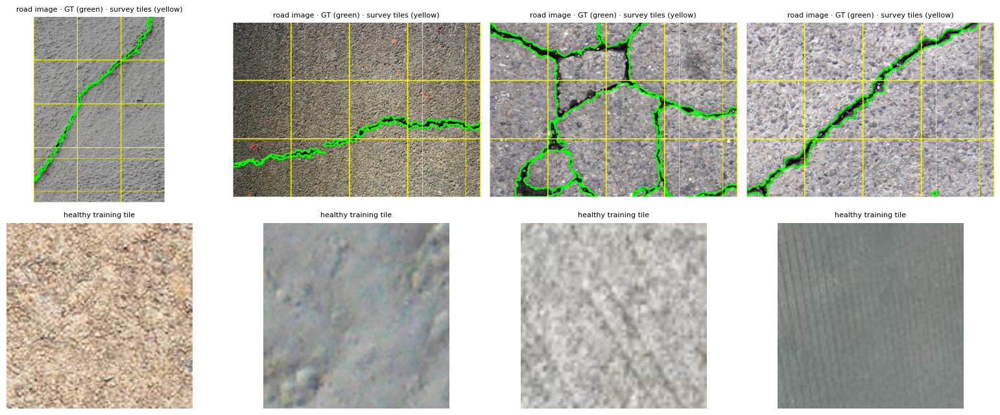

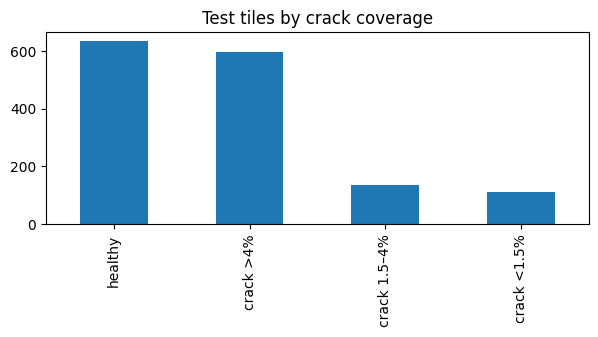

In [15]:
def draw_contour(img, mask, color=(0, 255, 0), th=2):
    out = img.copy()
    cs, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, cs, -1, color, th)
    return out

fig, ax = plt.subplots(2, 4, figsize=(16, 6.5))
for i in range(4):
    im, m = read_pair(*D['test_pairs'][i * 7 % len(D['test_pairs'])])
    vis = draw_contour(im, m)
    for y in tile_pos(im.shape[0], T):
        for x in tile_pos(im.shape[1], T):
            cv2.rectangle(vis, (x, y), (x + T - 1, y + T - 1), (255, 255, 0), 1)
    ax[0, i].imshow(vis); ax[0, i].axis('off'); ax[0, i].set_title('road image · GT (green) · survey tiles (yellow)', fontsize=8)
    ax[1, i].imshow(D['train'][i * 11]); ax[1, i].axis('off'); ax[1, i].set_title('healthy training tile', fontsize=8)
plt.tight_layout(); plt.savefig(FIG('01_samples.png'), dpi=110); plt.show()

pd.Series(D['test_types']).value_counts().plot.bar(title='Test tiles by crack coverage', figsize=(7, 2.5)); plt.show()

## 2 · Shared utilities & metrics

Tile-level metrics: image AUROC (healthy vs distressed tile), pixel AUROC and **AUPRO** (region-level crack localization). At the calibrated threshold, results are reported in road-maintenance terms:

* **Miss rate:** distressed tiles reported as healthy. Missed distress is how small cracks grow into potholes.
* **False-alarm rate:** healthy tiles flagged. Every false alarm costs a wasted inspection or maintenance trip.

In [16]:
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

def to_tensor(imgs):
    x = (imgs.astype(np.float32) / 255. - MEAN) / STD
    return torch.from_numpy(np.ascontiguousarray(x.transpose(0, 3, 1, 2)))

def gblur(t, sigma=None):
    sigma = sigma or CFG['smooth_sigma']
    k = int(2 * round(3 * sigma) + 1)
    return TF.gaussian_blur(t, [k, k], [sigma, sigma])

def topk_mean(maps, k=100):
    flat = maps.reshape(len(maps), -1); k = min(k, flat.shape[1])
    return np.partition(flat, -k, axis=1)[:, -k:].mean(1)

def aupro(masks, maps, max_fpr=0.3, n_th=200):
    regions = []
    for i, m in enumerate(masks):
        if m.any():
            n, lab = cv2.connectedComponents(m.astype(np.uint8))
            regions += [maps[i][lab == k] for k in range(1, n)]
    if not regions:
        return float('nan')
    neg = np.sort(maps[~masks])
    ths = np.quantile(neg, 1 - np.linspace(0, max_fpr, n_th))
    fprs = 1 - np.searchsorted(neg, ths, side='left') / len(neg)
    pros = np.array([np.mean([(r >= t).mean() for r in regions]) for t in ths])
    o = np.argsort(fprs); fprs, pros = fprs[o], pros[o]
    keep = fprs <= max_fpr
    trap = getattr(np, 'trapezoid', None) or np.trapz
    return float(trap(pros[keep], fprs[keep]) / max_fpr)

def evaluate(name, scores, maps, D, thr=None):
    y, M = D['test_labels'], D['test_masks']
    r = {'method': name, 'image_AUROC': roc_auc_score(y, scores)}
    gt, pr = M.reshape(-1), maps.reshape(-1)
    if gt.size > 4_000_000:
        idx = np.random.default_rng(0).choice(gt.size, 4_000_000, replace=False)
        gt, pr = gt[idx], pr[idx]
    r['pixel_AUROC'] = roc_auc_score(gt, pr)
    r['AUPRO@30%'] = aupro(M, maps)
    p, rc, _ = precision_recall_curve(y, scores)
    r['tile_F1max'] = float(np.max(2 * p * rc / (p + rc + 1e-8)))
    if thr is not None:
        pred = scores >= thr
        tp, fn = (pred & (y == 1)).sum(), (~pred & (y == 1)).sum()
        fp, tn = (pred & (y == 0)).sum(), (~pred & (y == 0)).sum()
        r['miss_rate'] = fn / max(tp + fn, 1)
        r['false_alarm_rate'] = fp / max(fp + tn, 1)
        r['precision@thr'] = tp / max(tp + fp, 1)
    return {k: (float(v) if not isinstance(v, str) else v) for k, v in r.items()}

def calibrate(val_scores, val_maps):
    # From healthy road only: 3-sigma rule for tiles, 99.9th percentile for pixels
    return dict(img_thr=float(val_scores.mean() + 3 * val_scores.std()),
                pix_thr=float(np.quantile(val_maps, 0.999)))

R = {}
def register(name, predict_fn, D):
    t0 = time.time()
    test_maps, test_scores = predict_fn(D['test'])
    ms = (time.time() - t0) / len(D['test']) * 1000
    val_maps, val_scores = predict_fn(D['val'])
    cal = calibrate(val_scores, val_maps)
    met = evaluate(name, test_scores, test_maps, D, cal['img_thr'])
    met['ms/tile'] = ms
    R[name] = dict(fn=predict_fn, maps=test_maps.astype(np.float32), scores=test_scores,
                   val_maps=val_maps.astype(np.float32), val_scores=val_scores, cal=cal, metrics=met,
                   vis=(float(np.percentile(val_maps, 50)), float(np.percentile(test_maps, 99.9))))
    print({k: round(v, 4) if isinstance(v, float) else v for k, v in met.items()})

## 3 · Baseline: classical crack detection

Many deployed pavement-survey systems still rely on hand-crafted filters. This baseline combines two of them:

1. **CLAHE** to equalize uneven lighting and shadows from trees, vehicles and buildings.
2. **Morphological black-hat** (closing − image): highlights thin structures darker than their surroundings, the typical look of a crack.
3. **Frangi ridge filter** (Hessian eigenvalues at several scales): responds to elongated, line-like dark ridges.

Both responses are standardized against healthy-road statistics and averaged. The weakness: road texture, joints, lane markings and shadows also produce dark ridges.

healthy-road stats:   0%|          | 0/300 [00:00<?, ?it/s]

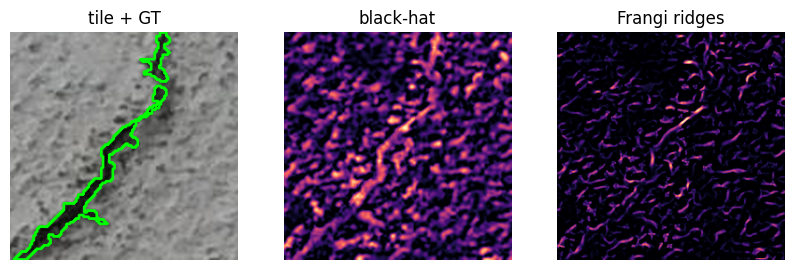

{'method': 'Classical (black-hat + Frangi)', 'image_AUROC': 0.598, 'pixel_AUROC': 0.4913, 'AUPRO@30%': 0.4042, 'tile_F1max': 0.7444, 'miss_rate': 1.0, 'false_alarm_rate': 0.0, 'precision@thr': 0.0, 'ms/tile': 161.5512}


In [17]:
CLAHE = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
BH_KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))

def crack_response(im):
    g = cv2.GaussianBlur(CLAHE.apply(cv2.cvtColor(im, cv2.COLOR_RGB2GRAY)), (3, 3), 0)
    bh = cv2.morphologyEx(g, cv2.MORPH_BLACKHAT, BH_KERNEL).astype(np.float32) / 255.
    fr = frangi(g.astype(np.float32) / 255., sigmas=(1, 2, 3), black_ridges=True).astype(np.float32)
    return bh, fr

def classical_fit(healthy_tiles, n=300):
    sel = healthy_tiles[np.random.default_rng(0).choice(len(healthy_tiles), min(n, len(healthy_tiles)), replace=False)]
    bh, fr = map(np.stack, zip(*[crack_response(i) for i in tqdm(sel, desc='healthy-road stats')]))
    return dict(bh_mu=float(bh.mean()), bh_sd=float(bh.std() + 1e-6), fr_mu=float(fr.mean()), fr_sd=float(fr.std() + 1e-6))

def classical_predict(imgs, M=None):
    M = CL if M is None else M
    maps = []
    for im in imgs:
        bh, fr = crack_response(im)
        z = 0.5 * (bh - M['bh_mu']) / M['bh_sd'] + 0.5 * (fr - M['fr_mu']) / M['fr_sd']
        maps.append(cv2.GaussianBlur(z, (0, 0), CFG['smooth_sigma']))
    maps = np.stack(maps)
    return maps, np.percentile(maps.reshape(len(maps), -1), 99.5, axis=1)

CL = classical_fit(D['train'])
i = int(np.where(D['test_labels'] == 1)[0][0]); bh, fr = crack_response(D['test'][i])
fig, ax = plt.subplots(1, 3, figsize=(10, 3.4))
for a, im, t in zip(ax, [draw_contour(D['test'][i], D['test_masks'][i]), bh, fr], ['tile + GT', 'black-hat', 'Frangi ridges']):
    a.imshow(im, cmap='magma'); a.set_title(t); a.axis('off')
plt.show()
register('Classical (black-hat + Frangi)', classical_predict, D)

## 4 · PatchCore: memory-bank anomaly detection (from scratch)

Implementation of [Roth et al., CVPR 2022](https://arxiv.org/abs/2106.08265) with no anomaly-detection library. A memory bank of patch features from **healthy asphalt and concrete** represents what normal road texture looks like, and any patch far from every bank entry is distress.

* **Features:** frozen ImageNet WideResNet-50, layers 2 + 3, 3×3 neighbourhood aggregation, channels pooled to 1024-d.
* **Coreset:** greedy k-center selection with a random projection keeps 10% of patches while preserving coverage of normal road appearance.
* **Score:** distance to the nearest healthy-road patch.

In [18]:
@torch.no_grad()
def greedy_coreset(feats, n, proj_dim=128, seed=0):
    g = torch.Generator(device=feats.device).manual_seed(seed)
    proj = torch.randn(feats.shape[1], proj_dim, device=feats.device, generator=g) / math.sqrt(proj_dim)
    z = feats @ proj
    sel = [int(torch.randint(len(z), (1,), generator=g, device=feats.device).item())]
    mind = torch.linalg.norm(z - z[sel[0]], dim=1)
    for _ in tqdm(range(n - 1), desc='Greedy coreset', mininterval=2):
        i = int(torch.argmax(mind))
        sel.append(i)
        mind = torch.minimum(mind, torch.linalg.norm(z - z[i], dim=1))
    return torch.tensor(sel, device=feats.device)

class PatchCore:
    def __init__(self, coreset_ratio=0.1, emb_dim=1024, device=DEVICE):
        w = tvm.wide_resnet50_2(weights=tvm.Wide_ResNet50_2_Weights.IMAGENET1K_V1)
        self.net = nn.ModuleDict(dict(stem=nn.Sequential(w.conv1, w.bn1, w.relu, w.maxpool),
                                      l1=w.layer1, l2=w.layer2, l3=w.layer3)).to(device).eval()
        for p in self.net.parameters():
            p.requires_grad_(False)
        self.ratio, self.emb_dim, self.device, self.bank = coreset_ratio, emb_dim, device, None

    @torch.no_grad()
    def embed(self, x):
        n = self.net
        f2 = n['l2'](n['l1'](n['stem'](x)))
        f3 = n['l3'](f2)
        f2, f3 = F.avg_pool2d(f2, 3, 1, 1), F.avg_pool2d(f3, 3, 1, 1)
        f3 = F.interpolate(f3, size=f2.shape[-2:], mode='bilinear', align_corners=False)
        f = torch.cat([f2, f3], 1)
        B, C, h, w = f.shape
        f = F.adaptive_avg_pool1d(f.permute(0, 2, 3, 1).reshape(-1, 1, C), self.emb_dim)
        return f.reshape(B, h, w, self.emb_dim)

    def fit(self, imgs, bs=16):
        feats = torch.cat([self.embed(to_tensor(imgs[i:i + bs]).to(self.device)).reshape(-1, self.emb_dim)
                           for i in tqdm(range(0, len(imgs), bs), desc='Extract features')])
        n = max(1, int(len(feats) * self.ratio))
        self.bank = feats[greedy_coreset(feats, n)].contiguous()
        print(f'Memory bank: {len(feats):,} patches → coreset {n:,} ({self.bank.numel()*4/1e6:.0f} MB)')
        del feats; torch.cuda.empty_cache()
        return self

    @torch.no_grad()
    def predict(self, imgs, bs=8):
        maps = []
        for i in range(0, len(imgs), bs):
            x = to_tensor(imgs[i:i + bs]).to(self.device)
            f = self.embed(x); B, h, w, C = f.shape
            q = f.reshape(-1, C)
            d = torch.cat([torch.cdist(q[j:j + 4096], self.bank).min(1).values for j in range(0, len(q), 4096)])
            m = F.interpolate(d.reshape(B, 1, h, w), size=x.shape[-2:], mode='bilinear', align_corners=False)
            maps.append(gblur(m)[:, 0].cpu().numpy())
        maps = np.concatenate(maps)
        return maps, maps.reshape(len(maps), -1).max(1)

t0 = time.time()
bank_sel = np.random.default_rng(CFG['seed']).choice(len(D['train']), min(CFG['bank_tiles'], len(D['train'])), replace=False)
pc = PatchCore(CFG['coreset_ratio']).fit(D['train'][bank_sel])
print(f'PatchCore fitted in {time.time()-t0:.0f}s')
register('PatchCore', pc.predict, D)

Downloading: "https://download.pytorch.org/models/wide_resnet50_2-95faca4d.pth" to /root/.cache/torch/hub/checkpoints/wide_resnet50_2-95faca4d.pth


100%|██████████| 132M/132M [00:00<00:00, 175MB/s]  


Extract features:   0%|          | 0/19 [00:00<?, ?it/s]

Greedy coreset:   0%|          | 0/30719 [00:00<?, ?it/s]

Memory bank: 307,200 patches → coreset 30,720 (126 MB)
PatchCore fitted in 69s
{'method': 'PatchCore', 'image_AUROC': 0.9595, 'pixel_AUROC': 0.9524, 'AUPRO@30%': 0.689, 'tile_F1max': 0.9268, 'miss_rate': 0.9799, 'false_alarm_rate': 0.0032, 'precision@thr': 0.8947, 'ms/tile': 29.0044}


## 5 · SynthSeg: a U-Net trained on procedurally generated road distress

The second detector teaches a compact segmentation network what road distress looks like **without real labels**, by painting synthetic distress onto healthy tiles (inspired by [DRAEM, ICCV 2021](https://arxiv.org/abs/2108.07610)) and using the painted mask as the label:

* **Cracks (60%):** branching random walks with varying width, darkened and softly blended. These mimic longitudinal, transverse and alligator cracking.
* **Potholes, patches, stains (40%):** thresholded, rotated Perlin-noise blobs filled with another road texture, block-shuffled surface, solid contamination such as oil or paint, or random texture.
* **Model:** U-Net with an ImageNet ResNet-18 encoder (14M params), focal + Dice loss, mixed precision, OneCycle LR, and full rotation/flip augmentation, since road tiles have no canonical orientation.

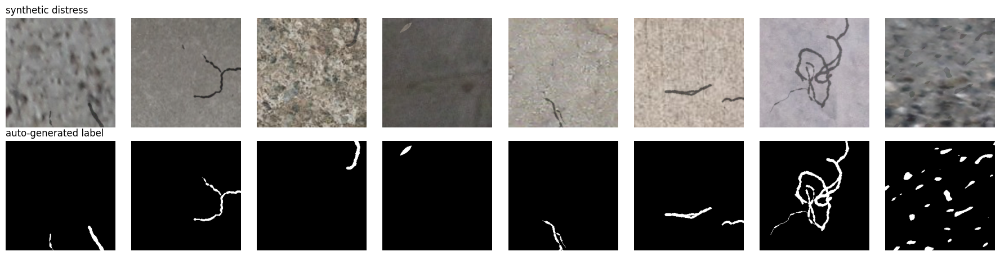

In [19]:
def perlin_2d(shape, res, rng):
    fade = lambda t: 6 * t**5 - 15 * t**4 + 10 * t**3
    d = (shape[0] // res[0], shape[1] // res[1])
    grid = np.mgrid[0:res[0]:res[0] / shape[0], 0:res[1]:res[1] / shape[1]].transpose(1, 2, 0)[:shape[0], :shape[1]] % 1
    ang = 2 * np.pi * rng.random((res[0] + 1, res[1] + 1))
    grads = np.dstack((np.cos(ang), np.sin(ang)))
    tile = lambda g: g.repeat(d[0], 0).repeat(d[1], 1)
    g00, g10, g01, g11 = tile(grads[:-1, :-1]), tile(grads[1:, :-1]), tile(grads[:-1, 1:]), tile(grads[1:, 1:])
    gx, gy = grid[..., 0], grid[..., 1]
    n00 = gx * g00[..., 0] + gy * g00[..., 1]
    n10 = (gx - 1) * g10[..., 0] + gy * g10[..., 1]
    n01 = gx * g01[..., 0] + (gy - 1) * g01[..., 1]
    n11 = (gx - 1) * g11[..., 0] + (gy - 1) * g11[..., 1]
    t = fade(grid)
    n0 = n00 * (1 - t[..., 0]) + t[..., 0] * n10
    n1 = n01 * (1 - t[..., 0]) + t[..., 0] * n11
    return np.sqrt(2) * ((1 - t[..., 1]) * n0 + t[..., 1] * n1)

def perlin_mask(H, W, rng):
    for _ in range(10):
        res = (2 ** int(rng.integers(0, 6)), 2 ** int(rng.integers(0, 6)))
        n = perlin_2d((H, W), res, rng).astype(np.float32)
        R_ = cv2.getRotationMatrix2D((W / 2, H / 2), float(rng.uniform(-90, 90)), 1.0)
        n = cv2.warpAffine(n, R_, (W, H), borderMode=cv2.BORDER_REFLECT)
        m = (n > 0.5).astype(np.float32)
        if m.sum() > 50:
            return m
    return m

def crack_mask(H, W, rng):
    # Branching random-walk polylines with varying width: longitudinal / transverse / alligator-like cracks
    m = np.zeros((H, W), np.uint8)
    def walk(x, y, ang, steps, width):
        for _ in range(steps):
            ang += rng.normal(0, 0.3)
            step = rng.uniform(3, 8)
            nx, ny = x + step * np.cos(ang), y + step * np.sin(ang)
            cv2.line(m, (int(x), int(y)), (int(nx), int(ny)), 1, max(1, int(width + rng.integers(-1, 2))))
            x, y = nx, ny
            if rng.random() < 0.04 and width > 1:
                walk(x, y, ang + rng.choice([-1, 1]) * rng.uniform(0.5, 1.4), int(rng.integers(5, 25)), width - 1)
            if not (-20 < x < W + 20 and -20 < y < H + 20):
                break
    for _ in range(int(rng.integers(1, 4))):
        walk(rng.uniform(0, W), rng.uniform(0, H), rng.uniform(0, 2 * np.pi), int(rng.integers(20, 70)), int(rng.integers(2, 7)))
    return m.astype(np.float32)

def texture_source(imgs, rng, H, W):
    kind = int(rng.integers(4))
    base = imgs[rng.integers(len(imgs))].astype(np.float32) / 255.
    if kind == 0:     # other road texture, rotated, colour-shifted (patch / repair)
        src = np.rot90(base, int(rng.integers(4)))[..., rng.permutation(3)]
    elif kind == 1:   # block-shuffled surface (ravelling / broken surface)
        g = 8; bh, bw = H // g, W // g
        blocks = [base[i*bh:(i+1)*bh, j*bw:(j+1)*bw] for i in range(g) for j in range(g)]
        order = rng.permutation(len(blocks))
        src = np.concatenate([np.concatenate([blocks[order[i*g + j]] for j in range(g)], 1) for i in range(g)], 0)
    elif kind == 2:   # oil / paint / water stain
        src = np.ones((H, W, 3), np.float32) * rng.random(3).astype(np.float32)
        src += rng.normal(0, 0.03, (H, W, 3)).astype(np.float32)
    else:             # pothole-like dark organic texture
        src = cv2.GaussianBlur(rng.random((H, W, 3)).astype(np.float32), (0, 0), float(rng.uniform(1, 5)))
        src = (src - src.min()) / (src.max() - src.min() + 1e-6) * float(rng.uniform(0.2, 1.0))
    return np.ascontiguousarray(np.clip(src, 0, 1), dtype=np.float32)

def synth_distress(img, imgs, rng):
    H, W = img.shape[:2]
    if rng.random() < CFG['p_crack_synth']:
        m = crack_mask(H, W, rng)
        soft = cv2.GaussianBlur(m, (0, 0), 0.8)[..., None]
        dark = img * float(rng.uniform(0.15, 0.6)) + rng.normal(0, 0.02, img.shape).astype(np.float32)
        out = img * (1 - soft) + dark * soft
    else:
        m = perlin_mask(H, W, rng)
        src = texture_source(imgs, rng, H, W)
        beta = float(rng.uniform(0.0, 0.8))
        mm = m[..., None]
        out = img * (1 - mm) + (1 - beta) * src * mm + beta * img * mm
    return np.clip(out, 0, 1).astype(np.float32), m

def rand_dihedral(rng, *arrs):
    k, f = int(rng.integers(4)), rng.random() < 0.5
    out = []
    for a in arrs:
        a = np.rot90(a, k, axes=(0, 1))
        out.append(np.ascontiguousarray(a[:, ::-1] if f else a))
    return out

class SynthDistressDataset(torch.utils.data.Dataset):
    def __init__(self, imgs, length, p_defect=0.7):
        self.imgs, self.length, self.p = imgs, length, p_defect
    def __len__(self):
        return self.length
    def __getitem__(self, idx):
        rng = np.random.default_rng((torch.initial_seed() + idx * 7919) % 2**32)
        (img,) = rand_dihedral(rng, self.imgs[rng.integers(len(self.imgs))].astype(np.float32) / 255.)
        img = np.clip(img * rng.uniform(0.85, 1.15), 0, 1)
        if rng.random() < self.p:
            img, mask = synth_distress(img, self.imgs, rng)
        else:
            mask = np.zeros(img.shape[:2], np.float32)
        x = ((img - MEAN) / STD).transpose(2, 0, 1)
        return torch.from_numpy(np.ascontiguousarray(x)).float(), torch.from_numpy(mask[None].copy()).float()

class RealCrackDataset(torch.utils.data.Dataset):
    # Upper-bound reference only: uses the REAL pixel labels
    def __init__(self, imgs, masks, length, p_crack=0.7):
        self.imgs, self.masks, self.length, self.p = imgs, masks, length, p_crack
        has = masks.reshape(len(masks), -1).any(1)
        self.crack_idx, self.clean_idx = np.where(has)[0], np.where(~has)[0]
    def __len__(self):
        return self.length
    def __getitem__(self, idx):
        rng = np.random.default_rng((torch.initial_seed() + idx * 104729) % 2**32)
        pool = self.crack_idx if (rng.random() < self.p and len(self.crack_idx)) or not len(self.clean_idx) else self.clean_idx
        j = pool[rng.integers(len(pool))]
        img, m = rand_dihedral(rng, self.imgs[j].astype(np.float32) / 255., self.masks[j].astype(np.float32))
        img = np.clip(img * rng.uniform(0.85, 1.15), 0, 1)
        x = ((img - MEAN) / STD).transpose(2, 0, 1)
        return torch.from_numpy(np.ascontiguousarray(x)).float(), torch.from_numpy(m[None].copy()).float()

ds_vis = SynthDistressDataset(D['train'], 8, p_defect=1.0)
fig, ax = plt.subplots(2, 8, figsize=(18, 4.6))
for i in range(8):
    x, m = ds_vis[i]
    ax[0, i].imshow(np.clip(x.numpy().transpose(1, 2, 0) * STD + MEAN, 0, 1)); ax[1, i].imshow(m[0], cmap='gray')
    ax[0, i].axis('off'); ax[1, i].axis('off')
ax[0, 0].set_title('synthetic distress', loc='left'); ax[1, 0].set_title('auto-generated label', loc='left')
plt.tight_layout(); plt.savefig(FIG('02_synthetic_distress.png'), dpi=110); plt.show()

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 168MB/s] 


Train SynthSeg U-Net (label-free):   0%|          | 0/1500 [00:00<?, ?it/s]

SynthSeg U-Net (label-free): trained in 1.6 min | params 14.3M


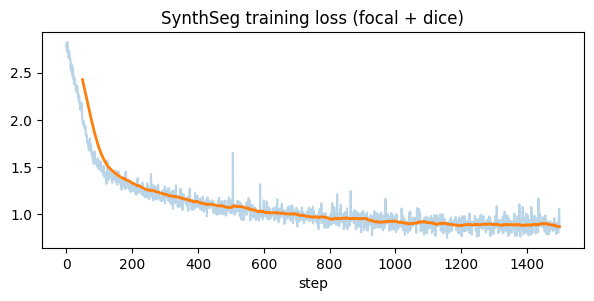

In [20]:
def conv_bn(i, o):
    return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True))

class Up(nn.Module):
    def __init__(self, i, o):
        super().__init__(); self.c = nn.Sequential(conv_bn(i, o), conv_bn(o, o))
    def forward(self, x, skip):
        x = F.interpolate(x, size=skip.shape[-2:], mode='bilinear', align_corners=False)
        return self.c(torch.cat([x, skip], 1))

class UNetR18(nn.Module):
    def __init__(self):
        super().__init__()
        r = tvm.resnet18(weights=tvm.ResNet18_Weights.IMAGENET1K_V1)
        self.enc0 = nn.Sequential(r.conv1, r.bn1, r.relu); self.pool = r.maxpool
        self.enc1, self.enc2, self.enc3, self.enc4 = r.layer1, r.layer2, r.layer3, r.layer4
        self.dec4, self.dec3 = Up(512 + 256, 256), Up(256 + 128, 128)
        self.dec2, self.dec1 = Up(128 + 64, 64), Up(64 + 64, 32)
        self.head = nn.Sequential(conv_bn(32, 16), nn.Conv2d(16, 1, 1))
    def forward(self, x):
        H, W = x.shape[-2:]
        e0 = self.enc0(x); e1 = self.enc1(self.pool(e0)); e2 = self.enc2(e1); e3 = self.enc3(e2); e4 = self.enc4(e3)
        d = self.dec1(self.dec2(self.dec3(self.dec4(e4, e3), e2), e1), e0)
        return self.head(F.interpolate(d, size=(H, W), mode='bilinear', align_corners=False))

def focal_dice_loss(logits, target, gamma=2.0):
    logits = logits.float()
    p = torch.sigmoid(logits)
    ce = F.binary_cross_entropy_with_logits(logits, target, reduction='none')
    pt = p * target + (1 - p) * (1 - target)
    focal = (ce * (1 - pt) ** gamma).mean()
    inter = (p * target).sum((1, 2, 3))
    dice = 1 - (2 * inter + 1) / (p.sum((1, 2, 3)) + target.sum((1, 2, 3)) + 1)
    return 10 * focal + dice.mean()

def train_unet(dataset, steps, tag):
    seed_everything(CFG['seed'])
    model = UNetR18().to(DEVICE)
    bs = CFG['seg_batch']
    loader = torch.utils.data.DataLoader(dataset, batch_size=bs, num_workers=2, drop_last=True, pin_memory=True)
    enc = [p for n, p in model.named_parameters() if n.startswith('enc')]
    dec = [p for n, p in model.named_parameters() if not n.startswith('enc')]
    lr = CFG['seg_lr']
    opt = torch.optim.AdamW([{'params': enc, 'lr': lr * 0.3}, {'params': dec, 'lr': lr}], weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[lr * 0.3, lr], total_steps=steps, pct_start=0.1)
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP)
    losses, t0 = [], time.time()
    model.train()
    pbar = tqdm(loader, total=steps, desc=f'Train {tag}')
    for step, (x, m) in enumerate(pbar):
        if step >= steps:
            break
        x, m = x.to(DEVICE, non_blocking=True), m.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            loss = focal_dice_loss(model(x), m)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt); nn.utils.clip_grad_norm_(model.parameters(), 5.0)
        scaler.step(opt); scaler.update(); sched.step()
        losses.append(loss.item())
        if step % 50 == 0:
            pbar.set_postfix(loss=f'{np.mean(losses[-50:]):.4f}')
    print(f'{tag}: trained in {(time.time()-t0)/60:.1f} min | params {sum(p.numel() for p in model.parameters())/1e6:.1f}M')
    return model.eval(), losses

steps = CFG['seg_steps']
seg_model, losses = train_unet(SynthDistressDataset(D['train'], steps * CFG['seg_batch']), steps, 'SynthSeg U-Net (label-free)')
plt.figure(figsize=(7, 2.8))
plt.plot(losses, alpha=.3); plt.plot(pd.Series(losses).rolling(50).mean(), lw=2)
plt.title('SynthSeg training loss (focal + dice)'); plt.xlabel('step'); plt.savefig(FIG('03_loss.png'), dpi=110); plt.show()

In [21]:
@torch.no_grad()
def seg_predict(imgs, model=None, bs=16):
    model = seg_model if model is None else model
    model.eval(); maps = []
    for i in range(0, len(imgs), bs):
        x = to_tensor(imgs[i:i + bs]).to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=USE_AMP):
            p = torch.sigmoid(model(x).float())
        maps.append(gblur(p.float())[:, 0].cpu().numpy())
    maps = np.concatenate(maps)
    return maps, topk_mean(maps, 100)

register('SynthSeg U-Net', seg_predict, D)

{'method': 'SynthSeg U-Net', 'image_AUROC': 0.7019, 'pixel_AUROC': 0.709, 'AUPRO@30%': 0.4671, 'tile_F1max': 0.7433, 'miss_rate': 0.7239, 'false_alarm_rate': 0.0269, 'precision@thr': 0.932, 'ms/tile': 4.4601}


## 6 · Fusion

PatchCore is strong on texture-level anomalies such as potholes, patches and ravelling. The synthetic-crack U-Net is sharp on thin, line-like cracks. Each map is standardized using **healthy calibration tiles only**, then the two are averaged.

In [22]:
PC_MU, PC_SD = float(R['PatchCore']['val_maps'].mean()), float(R['PatchCore']['val_maps'].std() + 1e-8)
SG_MU, SG_SD = float(R['SynthSeg U-Net']['val_maps'].mean()), float(R['SynthSeg U-Net']['val_maps'].std() + 1e-8)

def fusion_predict(imgs):
    pm, _ = pc.predict(imgs); sm, _ = seg_predict(imgs)
    fm = 0.5 * (pm - PC_MU) / PC_SD + 0.5 * (sm - SG_MU) / SG_SD
    return fm, topk_mean(fm, 50)

BEST = 'Fusion (PatchCore + SynthSeg)'
register(BEST, fusion_predict, D)

{'method': 'Fusion (PatchCore + SynthSeg)', 'image_AUROC': 0.7669, 'pixel_AUROC': 0.9201, 'AUPRO@30%': 0.701, 'tile_F1max': 0.7743, 'miss_rate': 0.6813, 'false_alarm_rate': 0.0269, 'precision@thr': 0.9406, 'ms/tile': 35.1619}


## 7 · How close does label-free get to a supervised model?

This trains the **same U-Net on the real pixel-level crack labels** as a ceiling for comparison. Because it uses annotations the other methods never see, it is a reference, not a competitor. The interesting number is how much of the supervised performance the label-free pipeline recovers.

In [23]:
SUP = 'Supervised U-Net (real labels · reference)'
if CFG['run_supervised_ref']:
    sup_model, _ = train_unet(RealCrackDataset(D['sup_imgs'], D['sup_masks'], steps * CFG['seg_batch']), steps, 'Supervised U-Net')
    register(SUP, lambda imgs: seg_predict(imgs, sup_model), D)
    for k in ['image_AUROC', 'pixel_AUROC', 'AUPRO@30%']:
        print(f"{k:12s}: label-free fusion reaches {R[BEST]['metrics'][k] / R[SUP]['metrics'][k] * 100:.1f}% of supervised")

Train Supervised U-Net:   0%|          | 0/1500 [00:00<?, ?it/s]

Supervised U-Net: trained in 1.6 min | params 14.3M
{'method': 'Supervised U-Net (real labels · reference)', 'image_AUROC': 0.9912, 'pixel_AUROC': 0.981, 'AUPRO@30%': 0.9353, 'tile_F1max': 0.9649, 'miss_rate': 0.0711, 'false_alarm_rate': 0.0079, 'precision@thr': 0.9937, 'ms/tile': 4.3747}
image_AUROC : label-free fusion reaches 77.4% of supervised
pixel_AUROC : label-free fusion reaches 93.8% of supervised
AUPRO@30%   : label-free fusion reaches 74.9% of supervised


## 8 · Results

,image_AUROC,pixel_AUROC,AUPRO@30%,tile_F1max,miss_rate,false_alarm_rate,ms/tile
method,,,,,,,
Classical (black-hat + Frangi),0.598,0.491,0.404,0.744,1.000,0.000,161.6
PatchCore,0.960,0.952,0.689,0.927,0.980,0.003,29.0
SynthSeg U-Net,0.702,0.709,0.467,0.743,0.724,0.027,4.5
Fusion (PatchCore + SynthSeg),0.767,0.920,0.701,0.774,0.681,0.027,35.2
Supervised U-Net (real labels · reference),0.991,0.981,0.935,0.965,0.071,0.008,4.4


miss / false-alarm rates use the 3σ threshold set from healthy calibration tiles only.


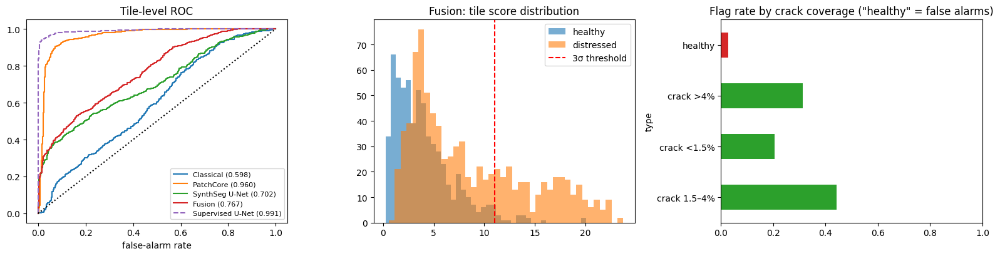

In [24]:
res = pd.DataFrame([R[k]['metrics'] for k in R]).set_index('method')
show = res[['image_AUROC', 'pixel_AUROC', 'AUPRO@30%', 'tile_F1max', 'miss_rate', 'false_alarm_rate', 'ms/tile']]
display(show.style.format({c: '{:.3f}' for c in show.columns if c != 'ms/tile'} | {'ms/tile': '{:.1f}'})
        .background_gradient(subset=['image_AUROC', 'pixel_AUROC', 'AUPRO@30%'], cmap='Greens'))
print('miss / false-alarm rates use the 3σ threshold set from healthy calibration tiles only.')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
for k in R:
    fpr, tpr, _ = roc_curve(D['test_labels'], R[k]['scores'])
    ax[0].plot(fpr, tpr, ls='--' if k == SUP else '-', label=f"{k.split(' (')[0]} ({R[k]['metrics']['image_AUROC']:.3f})")
ax[0].plot([0, 1], [0, 1], 'k:'); ax[0].set_title('Tile-level ROC'); ax[0].legend(fontsize=8); ax[0].set_xlabel('false-alarm rate')
sc, thr = R[BEST]['scores'], R[BEST]['cal']['img_thr']
ax[1].hist(sc[D['test_labels'] == 0], 40, alpha=.6, label='healthy'); ax[1].hist(sc[D['test_labels'] == 1], 40, alpha=.6, label='distressed')
ax[1].axvline(thr, c='r', ls='--', label='3σ threshold'); ax[1].legend(); ax[1].set_title('Fusion: tile score distribution')
per_type = pd.DataFrame({'type': D['test_types'], 'flagged': sc >= thr}).groupby('type').flagged.mean()
per_type.plot.barh(ax=ax[2], color=['tab:red' if t == 'healthy' else 'tab:green' for t in per_type.index])
ax[2].set_title('Flag rate by crack coverage ("healthy" = false alarms)'); ax[2].set_xlim(0, 1)
plt.tight_layout(); plt.savefig(FIG('04_results.png'), dpi=110); plt.show()

## 9 · From tiles to a road-condition report

A road agency doesn't want tile scores; it wants a **map of where the road is damaged and how badly**. Each road image is tiled, scored and stitched back into a full-resolution distress map. From that:

* **Flagged tiles** (red boxes): survey cells needing attention.
* **Crack length:** the skeleton length of the detected crack mask, in pixels. It converts to metres once the camera's ground resolution is known.
* **Distress density and severity:** an *illustrative* Good/Fair/Poor grade. Real indices like the Pavement Condition Index need calibrated survey data.

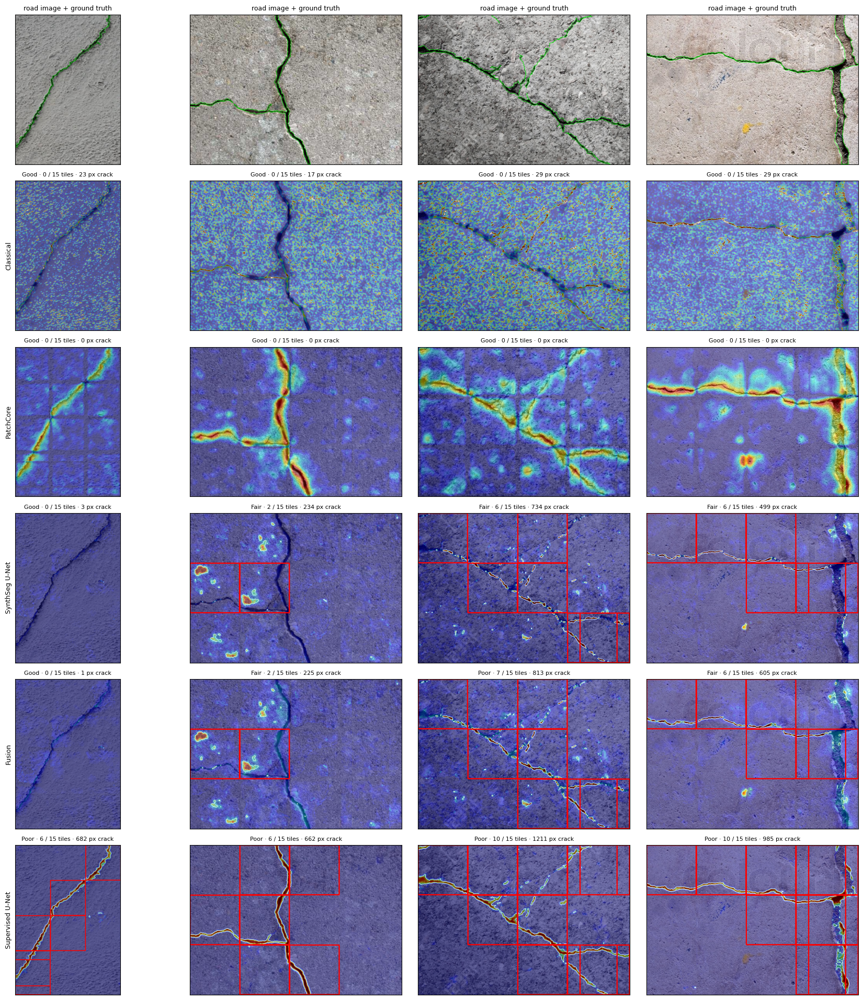

In [25]:
def heat_overlay(img, amap, lo, hi, pix_thr=None):
    a = np.clip((amap - lo) / (hi - lo + 1e-8), 0, 1)
    heat = cv2.applyColorMap((a * 255).astype(np.uint8), cv2.COLORMAP_JET)[..., ::-1]
    out = (0.55 * img + 0.45 * heat).astype(np.uint8)
    if pix_thr is not None:
        out = draw_contour(out, amap >= pix_thr, (255, 255, 255), 1)
    return out

def predict_full(img, method):
    H, W = img.shape[:2]
    if min(H, W) < T:
        f = T / min(H, W); img = cv2.resize(img, (int(np.ceil(W * f)), int(np.ceil(H * f)))); H, W = img.shape[:2]
    coords = [(y, x) for y in tile_pos(H, T) for x in tile_pos(W, T)]
    maps, scores = R[method]['fn'](upsample(np.stack([img[y:y + T, x:x + T] for y, x in coords])))
    acc, cnt = np.zeros((H, W), np.float32), np.zeros((H, W), np.float32)
    for (y, x), m in zip(coords, maps):
        acc[y:y + T, x:x + T] += cv2.resize(m.astype(np.float32), (T, T), interpolation=cv2.INTER_AREA)
        cnt[y:y + T, x:x + T] += 1
    return img, acc / np.maximum(cnt, 1), coords, scores

def road_report(img, method):
    t0 = time.time()
    img, full, coords, scores = predict_full(img, method)
    cal, (lo, hi) = R[method]['cal'], R[method]['vis']
    crack = cv2.morphologyEx((full >= cal['pix_thr']).astype(np.uint8), cv2.MORPH_OPEN, np.ones((2, 2), np.uint8)) > 0
    vis = heat_overlay(img, full, lo, hi, cal['pix_thr'])
    flagged = [(y, x) for (y, x), s in zip(coords, scores) if s >= cal['img_thr']]
    for y, x in flagged:
        cv2.rectangle(vis, (x, y), (x + T - 1, y + T - 1), (255, 0, 0), 2)
    density = float(crack.mean() * 100)
    return vis, {
        'severity (illustrative)': 'Good' if density < 0.5 else ('Fair' if density < 2 else 'Poor'),
        'flagged_tiles': f'{len(flagged)} / {len(coords)}',
        'distress_density_%': round(density, 2),
        'crack_length_px': int(skeletonize(crack).sum()),
        'latency_ms': round((time.time() - t0) * 1000, 1)}

ids = np.linspace(0, len(D['test_pairs']) - 1, 4).astype(int)
names = list(R)
fig, ax = plt.subplots(len(names) + 1, len(ids), figsize=(4.4 * len(ids), 3.2 * (len(names) + 1)))
for c, i in enumerate(ids):
    im, m = read_pair(*D['test_pairs'][i])
    ax[0, c].imshow(draw_contour(im, m, th=1)); ax[0, c].set_title('road image + ground truth', fontsize=9)
    for r, k in enumerate(names, 1):
        vis, rep = road_report(im, k)
        ax[r, c].imshow(vis)
        ax[r, c].set_title(f"{rep['severity (illustrative)']} · {rep['flagged_tiles']} tiles · {rep['crack_length_px']} px crack", fontsize=8)
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
for r, k in enumerate(names, 1): ax[r, 0].set_ylabel(k.split(' (')[0], fontsize=9)
plt.tight_layout(); plt.savefig(FIG('05_road_reports.png'), dpi=100); plt.show()

### Failure analysis

The hardest misses and false alarms of the fused model. Things to look for:

* **Hairline cracks** close to the texture scale of the asphalt.
* **Road texture, joints, shadows and markings** that resemble distress.
* **Label noise:** some "false alarms" may be real cracks the annotators skipped. This is worth checking by eye and makes a good interview discussion.

Missed: 575 / 844 distressed tiles | False alarms: 17 / 633 healthy tiles


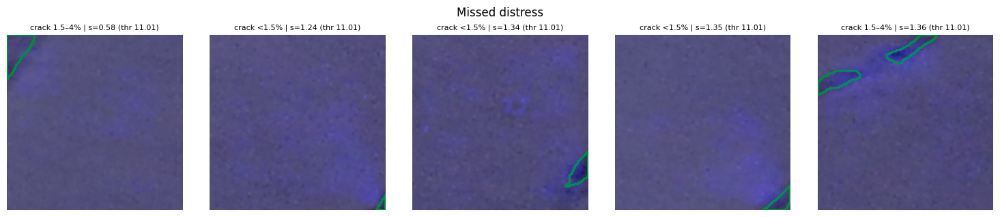

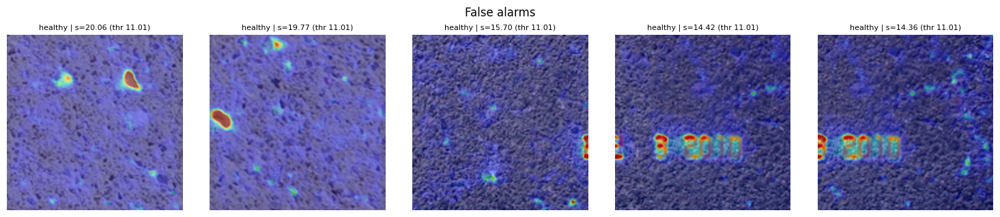

In [26]:
sc, thr, (lo, hi) = R[BEST]['scores'], R[BEST]['cal']['img_thr'], R[BEST]['vis']
y = D['test_labels']
miss = [i for i in np.argsort(sc) if y[i] == 1 and sc[i] < thr][:5]
fa = [i for i in np.argsort(-sc) if y[i] == 0 and sc[i] >= thr][:5]
print(f'Missed: {len(np.where((y == 1) & (sc < thr))[0])} / {y.sum()} distressed tiles | '
      f'False alarms: {len(np.where((y == 0) & (sc >= thr))[0])} / {(y == 0).sum()} healthy tiles')
for title, sel in [('Missed distress', miss), ('False alarms', fa)]:
    if not sel:
        print(f'{title}: none 🎉'); continue
    fig, ax = plt.subplots(1, len(sel), figsize=(3 * len(sel), 3.2), squeeze=False)
    for a, i in zip(ax[0], sel):
        a.imshow(heat_overlay(draw_contour(D['test'][i], D['test_masks'][i]), R[BEST]['maps'][i], lo, hi))
        a.set_title(f"{D['test_types'][i]} | s={sc[i]:.2f} (thr {thr:.2f})", fontsize=8); a.axis('off')
    plt.suptitle(title); plt.tight_layout(); plt.show()

## 10 · Edge deployment: can it keep up with a survey vehicle?

Survey vehicles, buses and dashcam fleets usually run on in-vehicle CPUs or small edge boards. The label-free U-Net is exported to **ONNX**, **statically quantized to INT8** with healthy calibration tiles (QDQ, per-channel), and benchmarked on CPU.

Latency is then translated into the **maximum survey speed** each runtime supports: if one camera frame covers `frame_coverage_m` metres of road and contains as many tiles as a DeepCrack-sized image, the system must finish a frame before the vehicle moves that distance. The coverage figure is an assumption you can change in `CFG`.

Colab's free CPU has only 2 cores, so real in-vehicle hardware with 4–8 cores or an NPU would be faster.

In [27]:
import onnxruntime as ort
from onnxruntime.quantization import quantize_static, CalibrationDataReader, QuantType, QuantFormat

onnx_fp32, onnx_int8 = FIG('synthseg_unet_fp32.onnx'), FIG('synthseg_unet_int8.onnx')
m_cpu = copy.deepcopy(seg_model).float().cpu().eval()
dummy = torch.randn(1, 3, S, S)
kw = dict(input_names=['image'], output_names=['logits'], opset_version=17,
          dynamic_axes={'image': {0: 'batch'}, 'logits': {0: 'batch'}})
try:
    torch.onnx.export(m_cpu, dummy, onnx_fp32, dynamo=False, **kw)
except TypeError:
    torch.onnx.export(m_cpu, dummy, onnx_fp32, **kw)

class CalibReader(CalibrationDataReader):
    def __init__(self, imgs):
        self.it = iter([{'image': to_tensor(imgs[i:i + 1]).numpy()} for i in range(len(imgs))])
    def get_next(self):
        return next(self.it, None)

try:
    calib = np.concatenate([D['val'][:64], D['train'][:64]])
    quantize_static(onnx_fp32, onnx_int8, CalibReader(calib), quant_format=QuantFormat.QDQ,
                    activation_type=QuantType.QUInt8, weight_type=QuantType.QInt8, per_channel=True)
except Exception as e:
    print('INT8 quantization failed:', e); onnx_int8 = None

so = ort.SessionOptions(); so.intra_op_num_threads = os.cpu_count()
sess = {'ONNX fp32 (CPU)': ort.InferenceSession(onnx_fp32, so, providers=['CPUExecutionProvider'])}
if onnx_int8:
    sess['ONNX INT8 (CPU)'] = ort.InferenceSession(onnx_int8, so, providers=['CPUExecutionProvider'])

def ort_predict(s):
    def f(imgs):
        lo_ = np.concatenate([s.run(None, {'image': to_tensor(imgs[i:i + 1]).numpy()})[0] for i in range(len(imgs))])
        p = gblur(torch.sigmoid(torch.from_numpy(lo_)))[:, 0].numpy()
        return p, topk_mean(p, 100)
    return f

def bench(fn, n=30, warm=5):
    for _ in range(warm): fn()
    t = time.perf_counter()
    for _ in range(n): fn()
    return (time.perf_counter() - t) / n * 1000

im0, _ = read_pair(*D['test_pairs'][0])
TILES_PER_FRAME = len(tile_pos(im0.shape[0], T)) * len(tile_pos(im0.shape[1], T))
survey_kmh = lambda ms_tile: CFG['frame_coverage_m'] / (ms_tile * TILES_PER_FRAME / 1000) * 3.6

x1 = to_tensor(D['test'][:1])
rows = []
if DEVICE == 'cuda':
    xg = x1.to(DEVICE)
    def gpu_run():
        with torch.no_grad(), torch.autocast('cuda', dtype=torch.float16):
            seg_model(xg)
        torch.cuda.synchronize()
    rows.append(dict(runtime='PyTorch fp16 (T4 GPU)', ms_per_tile=bench(gpu_run),
                     size_MB=sum(p.numel() for p in seg_model.parameters()) * 4 / 1e6,
                     image_AUROC=R['SynthSeg U-Net']['metrics']['image_AUROC'],
                     pixel_AUROC=R['SynthSeg U-Net']['metrics']['pixel_AUROC']))
ref = sess['ONNX fp32 (CPU)'].run(None, {'image': x1.numpy()})[0]
print('max |PyTorch − ONNX| logit diff:', float(np.abs(m_cpu(x1).detach().numpy() - ref).max()))
for name, s in sess.items():
    maps, scores = ort_predict(s)(D['test'])
    met = evaluate(name, scores, maps, D)
    path = onnx_fp32 if 'fp32' in name else onnx_int8
    rows.append(dict(runtime=name, ms_per_tile=bench(lambda: s.run(None, {'image': x1.numpy()})),
                     size_MB=os.path.getsize(path) / 1e6, image_AUROC=met['image_AUROC'], pixel_AUROC=met['pixel_AUROC']))
deploy = pd.DataFrame(rows).set_index('runtime')
deploy['max_survey_kmh'] = deploy['ms_per_tile'].apply(survey_kmh)
display(deploy.style.format('{:.3f}').format({'ms_per_tile': '{:.1f}', 'size_MB': '{:.1f}', 'max_survey_kmh': '{:.0f}'}))
print(f"Assumes {TILES_PER_FRAME} tiles per frame and {CFG['frame_coverage_m']} m of road per frame; "
      f"CPU cores here: {os.cpu_count()}")

max |PyTorch − ONNX| logit diff: 2.0742416381835938e-05


,ms_per_tile,size_MB,image_AUROC,pixel_AUROC,max_survey_kmh
runtime,,,,,
PyTorch fp16 (T4 GPU),7.0,57.3,0.701890,0.708955,104
ONNX fp32 (CPU),65.6,57.3,0.702079,0.709017,11
ONNX INT8 (CPU),48.6,14.5,0.752839,0.682495,15


Assumes 15 tiles per frame and 3.0 m of road per frame; CPU cores here: 4


## 11 · Interactive road inspection demo (Gradio)

Upload a road-surface photo or click an example. The demo returns the distress heatmap, detected crack outlines (white), flagged survey tiles (red) and a condition summary. It prints a public `gradio.live` link you can share with recruiters for about a week.

Tip: the model was calibrated on close-up pavement images, so results are best on top-down or near-top-down road photos at similar scale. A forward-facing dashcam view would need a perspective (bird's-eye) warp first.

In [28]:
import gradio as gr

def inspect(image, method):
    if image is None:
        return None, {}
    if image.ndim == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    image = image[..., :3].astype(np.uint8)
    if max(image.shape[:2]) > 1024:              # keep the tile count manageable
        f = 1024 / max(image.shape[:2]); image = cv2.resize(image, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    return road_report(image, method)

demo = gr.Interface(
    fn=inspect,
    inputs=[gr.Image(type='numpy', label='Road surface image'),
            gr.Radio(list(R), value=BEST, label='Detector')],
    outputs=[gr.Image(label='Distress map · crack outlines (white) · flagged tiles (red)'), gr.JSON(label='Road condition report')],
    examples=[[D['test_pairs'][i][0], BEST] for i in ids],
    title='RoadScan AI · road surface distress inspection',
    description='Label-free crack and distress detection, trained on healthy road only.')
demo.launch(share=True, debug=False)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://c9aaffa89275a832d5.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12 · Save everything (optionally to Google Drive)

In [29]:
torch.save(seg_model.state_dict(), FIG('synthseg_unet.pt'))
torch.save({'bank': pc.bank.half().cpu(), 'emb_dim': pc.emb_dim}, FIG('patchcore_bank_fp16.pt'))
summary = {'dataset': D['name'], 'config': CFG,
           'metrics': {k: R[k]['metrics'] for k in R},
           'calibration': {k: R[k]['cal'] for k in R},
           'deployment': deploy.reset_index().to_dict('records')}
with open(FIG('results.json'), 'w') as f:
    json.dump(summary, f, indent=2, default=float)
print('Saved to', CFG['out_dir'], '→', sorted(os.listdir(CFG['out_dir'])))

SAVE_TO_DRIVE = False   # set True to keep results after the Colab session ends
if SAVE_TO_DRIVE:
    from google.colab import drive
    import shutil
    drive.mount('/content/drive')
    dst = f"/content/drive/MyDrive/RoadScan/{D['name']}"
    shutil.copytree(CFG['out_dir'], dst, dirs_exist_ok=True); print('Copied to', dst)

Saved to /kaggle/working/outputs → ['01_samples.png', '02_synthetic_distress.png', '03_loss.png', '04_results.png', '05_road_reports.png', 'patchcore_bank_fp16.pt', 'results.json', 'synthseg_unet.pt', 'synthseg_unet_fp32.onnx', 'synthseg_unet_int8.onnx']


## 13 · (Optional) New city, new camera: cross-dataset test

Every city has different asphalt, lighting and cameras. Flip `RUN_CROSS = True` to evaluate the models trained above on the **other** dataset (DeepCrack ↔ CrackForest):

1. **Zero-shot:** use the models as they are.
2. **Re-fit PatchCore on healthy target-city road:** takes a few minutes and needs **no labels**. This is a key practical advantage of the label-free approach.

In [30]:
RUN_CROSS = False

if RUN_CROSS:
    other = 'cfd' if CFG['dataset'] == 'deepcrack' else 'deepcrack'
    D2 = load_dataset(other)
    rows = []
    for k in [k for k in R if k != SUP]:
        m, s = R[k]['fn'](D2['test'])
        rows.append(evaluate(f'{k} · zero-shot', s, m, D2))
    sel = np.random.default_rng(0).choice(len(D2['train']), min(CFG['bank_tiles'], len(D2['train'])), replace=False)
    pc2 = PatchCore(CFG['coreset_ratio']).fit(D2['train'][sel])
    m, s = pc2.predict(D2['test'])
    rows.append(evaluate('PatchCore · re-fit on healthy target road (no labels)', s, m, D2))
    cross = pd.DataFrame(rows).set_index('method')[['image_AUROC', 'pixel_AUROC', 'AUPRO@30%']]
    print(f"Trained on {CFG['dataset']} → tested on {other}")
    display(cross.round(3)); cross.to_csv(FIG('cross_city.csv'))
    del pc2, D2; gc.collect(); torch.cuda.empty_cache()

## 14 · README results snippet

In [31]:
cols = ['image_AUROC', 'pixel_AUROC', 'AUPRO@30%', 'miss_rate', 'false_alarm_rate', 'ms/tile']
lines = [f"**Dataset:** `{D['name']}` · {len(D['test'])} test tiles · T4 GPU · thresholds from healthy road only\n",
         '| Method | ' + ' | '.join(cols) + ' |', '|' + '---|' * (len(cols) + 1)]
for k in R:
    m = R[k]['metrics']
    lines.append(f'| {k} | ' + ' | '.join(f'{m[c]:.1f}' if c == 'ms/tile' else f'{m[c]:.3f}' for c in cols) + ' |')
lines += ['', '| Runtime | ms/tile | size MB | tile AUROC | pixel AUROC | max survey km/h |', '|---|---|---|---|---|---|']
for k, r in deploy.iterrows():
    lines.append(f"| {k} | {r.ms_per_tile:.1f} | {r.size_MB:.1f} | {r.image_AUROC:.3f} | {r.pixel_AUROC:.3f} | {r.max_survey_kmh:.0f} |")
print('\n'.join(lines))

**Dataset:** `deepcrack` · 1477 test tiles · T4 GPU · thresholds from healthy road only

| Method | image_AUROC | pixel_AUROC | AUPRO@30% | miss_rate | false_alarm_rate | ms/tile |
|---|---|---|---|---|---|---|
| Classical (black-hat + Frangi) | 0.598 | 0.491 | 0.404 | 1.000 | 0.000 | 161.6 |
| PatchCore | 0.960 | 0.952 | 0.689 | 0.980 | 0.003 | 29.0 |
| SynthSeg U-Net | 0.702 | 0.709 | 0.467 | 0.724 | 0.027 | 4.5 |
| Fusion (PatchCore + SynthSeg) | 0.767 | 0.920 | 0.701 | 0.681 | 0.027 | 35.2 |
| Supervised U-Net (real labels · reference) | 0.991 | 0.981 | 0.935 | 0.071 | 0.008 | 4.4 |

| Runtime | ms/tile | size MB | tile AUROC | pixel AUROC | max survey km/h |
|---|---|---|---|---|---|
| PyTorch fp16 (T4 GPU) | 7.0 | 57.3 | 0.702 | 0.709 | 104 |
| ONNX fp32 (CPU) | 65.6 | 57.3 | 0.702 | 0.709 | 11 |
| ONNX INT8 (CPU) | 48.6 | 14.5 | 0.753 | 0.682 | 15 |
